In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer, InputExample, losses
from sentence_transformers.evaluation import EmbeddingSimilarityEvaluator
from torch.utils.data import DataLoader
from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_absolute_error, mean_squared_error, classification_report
import json, warnings
warnings.filterwarnings('ignore')

print('Libraries imported!')

c:\Users\Tanvi\OneDrive\Desktop\ATS_SCORER\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported!


C:\Users\Tanvi\AppData\Local\Temp\ipykernel_18196\4166890017.py:5: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, InputExample, losses
C:\Users\Tanvi\AppData\Local\Temp\ipykernel_18196\4166890017.py:6: DeprecationWarning: Importing from 'sentence_transformers.evaluation' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.evaluation' instead.
  from sentence_transformers.evaluation import EmbeddingSimilarityEvaluator


In [2]:
# Load the cleaned ATS pairs dataset

df = pd.read_csv('../dataset/cleaned_resumeJD_pairs.csv')
print(f"Loaded: {len(df)} pairs")
print(f"\nLabel distribution:")
print(df['match_label'].value_counts())
print(f"\nScore range: {df["match_score"].min()}")

df.head(3)

Loaded: 280 pairs

Label distribution:
match_label
medium    110
high       93
low        77
Name: count, dtype: int64

Score range: 0.06


,resume_text,job_description,match_label,match_score,match_label_lower,resume_len,jd_len
0,BI Analyst with 7 years of experience based in...,Fathom is hiring a Financial Analyst (Berlin)....,medium,0.53,medium,75,71
1,Data Scientist with 13 years of experience bas...,Lumen is hiring a Senior UX Designer (Singapor...,low,0.26,low,79,74
2,Software Engineer with 8 years of experience b...,Acme Corp is hiring a Product Manager (Seattle...,low,0.31,low,71,80


In [3]:
train_df, temp_df = train_test_split(
    df, test_size=0.3, random_state=42, stratify=df['match_label']
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify= temp_df['match_label']
)

print(f"Train:      {len(train_df)} pairs")
print(f"Validation:       {len(val_df)} pairs")
print(f"Test:     {len(test_df)} pairs")
print()

# Verify each split has all 3 labels 
for name, split in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f"{name} label dist: {split["match_label"].value_counts().to_dict()}")


Train:      196 pairs
Validation:       42 pairs
Test:     42 pairs

Train label dist: {'medium': 77, 'high': 65, 'low': 54}
Val label dist: {'medium': 16, 'high': 14, 'low': 12}
Test label dist: {'medium': 17, 'high': 14, 'low': 11}


In [4]:
# Covert to InputExample format -- sentence-transformers expect this
# text1 => resume, text2 => JD , labels => match_score(float 0-1)

train_examples = [
    InputExample(texts= [row['resume_text'], row['job_description']], label=float(row['match_score']))
    for _, row in train_df.iterrows()
]


val_examples = [
    InputExample(texts= [row['resume_text'], row['job_description']], label= float(row['match_score']))
    for _, row in val_df.iterrows()
]


print(f"Train examples: {len(train_examples)}")
print(f"Validation examples: {len(val_examples)}")
print(f"\nSample InputExample:")
print(f"text1 (resume): {train_examples[0].texts[0][:80]}...")
print(f"text2 (JD): {train_examples[0].texts[1][:80]}... ")
print(f"label: {train_examples[0].label}")

Train examples: 196
Validation examples: 42

Sample InputExample:
text1 (resume): Site Reliability Engineer with 6 years of experience based in Toronto. M.S. in H...
text2 (JD): TechNova is hiring a Associate Product Manager (Seattle). In this role you will ... 
label: 0.15


In [5]:
print("loading base BERT model")
base_model = SentenceTransformer("all-mpnet-base-v2")
print("model succesfully loaded")

loading base BERT model


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 574.45it/s]


model succesfully loaded


In [6]:
# Evaluate the base model on test set before fine-tuning
# this is our baseline, fine-tuning should beat this.
print("Evaluating base model on test set....")

base_preds = []
for _, row in test_df.iterrows():
    emb1 = base_model.encode(row['resume_text'])
    emb2 = base_model.encode(row["job_description"])
    sim = cosine_similarity([emb1], [emb2])[0][0]
    base_preds.append(float(sim))

base_mae = mean_absolute_error(test_df['match_score'], base_preds)
base_rmse = np.sqrt(mean_absolute_error(test_df['match_score'], base_preds))

print(f"Base Model -- Test Set Performance")
print(f"MAE: {base_mae:.4f}")
print(f"RMSE: {base_rmse:.4f}")
print()
print("Goal: fine-tuning should reduce MAE below this number")

Evaluating base model on test set....
Base Model -- Test Set Performance
MAE: 0.1946
RMSE: 0.4412

Goal: fine-tuning should reduce MAE below this number


In [7]:
model = SentenceTransformer("all-mpnet-base-v2")
train_dataloader = DataLoader(train_examples, shuffle=True, batch_size=16)
train_loss = losses.CosineSimilarityLoss(model)

evaluator = EmbeddingSimilarityEvaluator.from_input_examples(
    val_examples, name = 'ats-val'
)

print("Training setup ready")
print(f"Batch size: 16")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 608.33it/s]


Training setup ready
Batch size: 16


In [8]:
total_steps = len(train_dataloader) * 10
warmup_steps = int(total_steps * 0.1)

print(f"Total steps: {total_steps}")
print(f"Warmup steps: {warmup_steps}")

print("\nStarting fine-tuning....\n")

model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    evaluator=evaluator,
    epochs=10,
    evaluation_steps=len(train_dataloader),
    warmup_steps=warmup_steps,
    output_path="models/finetuned-bert",
    save_best_model=True,
    use_amp=True,
    show_progress_bar=True
)

print("\nFINE TUNING COMPLETE!!")

Total steps: 130
Warmup steps: 13

Starting fine-tuning....



Step,Training Loss,Validation Loss,Ats-val Pearson Cosine,Ats-val Spearman Cosine
13,No log,No log,0.710927,0.700912
26,No log,No log,0.732800,0.713319
39,No log,No log,0.730451,0.706994
52,No log,No log,0.742443,0.723536
65,No log,No log,0.752068,0.728725
78,No log,No log,0.756700,0.743158
91,No log,No log,0.758129,0.742104
104,No log,No log,0.759496,0.745672
117,No log,No log,0.760505,0.741375
130,No log,No log,0.760568,0.741375


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.50it/s]



FINE TUNING COMPLETE!!


In [9]:
finetuned_model = SentenceTransformer("models/finetuned-bert")
print("Fine-Tuned model loaded!")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 662.73it/s]


Fine-Tuned model loaded!


In [10]:
ft_preds = []
for _, row in test_df.iterrows():
    emb1 = finetuned_model.encode(row['resume_text'])
    emb2 = finetuned_model.encode(row["job_description"])
    sim = cosine_similarity([emb1], [emb2])[0][0]
    ft_preds.append(float(sim))


ft_mae = mean_absolute_error(test_df['match_score'], ft_preds)
ft_rmse = np.sqrt(mean_squared_error(test_df['match_score'], ft_preds))


print(f"\nFine-tuned model -- test set performance")
print(f"MAE: {ft_mae: .4f}")
print(f"RMSE: {ft_rmse: .4f}")


Fine-tuned model -- test set performance
MAE:  0.0985
RMSE:  0.1233


In [16]:
# side by side comparison

print('=' * 50)
print("MODEL COMPARISON")
print("=" * 50)
print(f'Base MAE: {base_mae:.4f}')
print(f"Fine-tuned MAE: {ft_mae:.4f}")
print(f"Improvement: {(base_mae - ft_mae)/ base_mae * 100:.2f} %")


print("=" * 50)

MODEL COMPARISON
Base MAE: 0.1946
Fine-tuned MAE: 0.0985
Improvement: 49.38 %


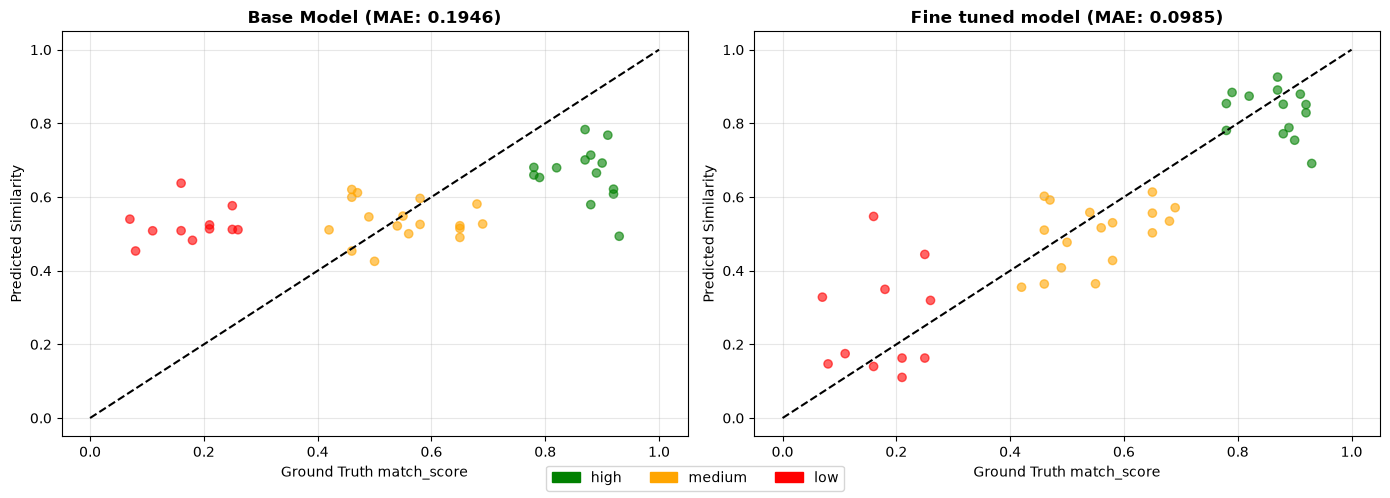

In [19]:
# Scatter plots: base vs fine tuned 
fig, axes = plt.subplots(1, 2, figsize= (14, 5))
colors = test_df['match_label'].map({'low': 'red', 'medium': 'orange', 'high': 'green'})


for ax, preds, title, mae in [
    (axes[0], base_preds, 'Base Model', base_mae),
    (axes[1], ft_preds, 'Fine tuned model', ft_mae)
]:
    ax.scatter(test_df['match_score'], preds, c=colors, alpha=0.6)
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect prediction')
    ax.set_xlabel('Ground Truth match_score')
    ax.set_ylabel('Predicted Similarity')
    ax.set_title(f"{title} (MAE: {mae:.4f})",  fontweight='bold')
    ax.grid(True, alpha= 0.3)


from matplotlib.patches import Patch
fig.legend(handles=[
    Patch(color='green', label='high'),
    Patch(color='orange', label='medium'),
    Patch(color='red', label='low'),
], loc= 'lower center', ncol=3)

plt.tight_layout()
plt.show()

In [20]:
metadata = {
    'base_model' : 'all-mpnet-base-v2',
    'dataset' : 'merged_dataset_clean.csv',
    'total_pairs' : len(df),
    'train_pairs' : len(train_df),
    'val_pairs' : len(val_df),
    'test_pairs' : len(test_df),
    'epochs' : 10, 
    'batch_size' : 16,
    'base_mae' : round(float(base_mae)),
    'finetuned_mae' : round(float(ft_mae)),
    'improvement_pct' : round((base_mae - ft_mae) / base_mae * 100)
}


with open("models/finetuned-bert/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print('Saved: models/finetuned-bert/')
print(json.dumps(metadata, indent=2))

Saved: models/finetuned-bert/
{
  "base_model": "all-mpnet-base-v2",
  "dataset": "merged_dataset_clean.csv",
  "total_pairs": 280,
  "train_pairs": 196,
  "val_pairs": 42,
  "test_pairs": 42,
  "epochs": 10,
  "batch_size": 16,
  "base_mae": 0,
  "finetuned_mae": 0,
  "improvement_pct": 49
}
